# TKG4 firn beneath seasonal snow

Follow the continuous WY2020–WY2026 SNOWPACK 3.7.0 simulation with lapse-rate-adjusted HRRR-AK forcing. TKG4 retains WY2020 snow and the selected run covers every measured pit density interval. The model point is about 8 m horizontally from the pit and 53 m higher in the recorded metadata.

The July 8, 2021 density samples are compared with one simulated profile at local noon. The field sheet records the sampling date without an hour. Timeline dates are in Juneau and layer heights are relative to the model base. The pit comparison aligns profiles by depth below their respective surfaces.

In [1]:
import csv
from datetime import datetime
import mmap
import os
from pathlib import Path
import sys
from zoneinfo import ZoneInfo

from IPython.display import display
import matplotlib as mpl
from matplotlib.collections import PolyCollection
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd()
root = next(p for p in (cwd, *cwd.parents, cwd / 'jif_snow_modeling')
            if (p / 'sites/radar_sites/scripts/compare_model_pit_radar.py').is_file())
sys.path.insert(0, str(root / 'sites/radar_sites/scripts'))
from compare_model_pit_radar import RADAR_ROOT, load_pits
from prepare_radar_site_forcing import MODEL_ROOT, PERIOD, read_smet

model_root = Path(os.environ.get('RADAR_MODEL_ROOT', MODEL_ROOT)).expanduser()
radar_root = Path(os.environ.get('RADAR_DATA_ROOT', RADAR_ROOT)).expanduser()
run = model_root / 'tkg4/output' / f'hrrrak_lapserate_tkg4_{PERIOD}_heatflux_soiltemp_zero'
pit = load_pits(radar_root).loc['tkg4']
tz = ZoneInfo('America/Juneau')
snapshot = (pit.pit_swe_date + pd.Timedelta(hours=12)).tz_localize(tz)
pit_time = snapshot.tz_convert('UTC').tz_localize(None)
plt.style.use('seaborn-v0_8-darkgrid')

## Identify carryover using layer age

The age record gives an estimated deposition date when subtracted from the profile timestamp. Carryover layers predate the current water year, defined here as starting October 1 at 00:00 UTC. The modeled boundary is drawn where the older layers form a basal block under younger snow. Rounded ages and layer merging limit the precision of this diagnostic. The reader seeks directly to selected hours in the large profile file and checks their total depths against the companion hourly SMET. [SNOWPACK profile format](https://snowpack.slf.ch/doc-release/html/pro_format.html)

In [2]:
fields = {b'0501': 'top', b'0502': 'density', b'0503': 'temperature',
          b'0505': 'age', b'0506': 'water', b'0513': 'grain',
          b'0515': 'ice', b'0516': 'air'}
record_start = b'\n0500,'
time_format = '%d.%m.%Y %H:%M:%S'


def water_year(times):
    return np.asarray(times.year + (times.month >= 10), dtype=int)


def read_profile(data, stamp):
    marker = stamp.strftime(time_format).encode()
    low, high = data.find(b'\n[DATA]'), len(data)
    while low < high:
        middle = (low + high) // 2
        start = data.find(record_start, middle)
        if start < 0 or start >= high:
            high = middle
            continue
        line_end = data.find(b'\n', start + len(record_start))
        recorded = data[start + len(record_start):line_end].strip()
        if recorded == marker:
            break
        if datetime.strptime(recorded.decode(), time_format) < stamp:
            low = start + 1
        else:
            high = middle
    else:
        raise ValueError(f'Missing profile at {stamp} UTC')

    end = data.find(record_start, line_end)
    values = {}
    for line in data[line_end + 1:end if end >= 0 else len(data)].splitlines():
        name = fields.get(line[:4])
        if name is None:
            continue
        _, count, payload = line.split(b',', 2)
        array = np.fromstring(payload.decode(), sep=',')
        if len(array) != int(count) or not np.isfinite(array).all():
            raise ValueError(f'Invalid {name} record at {stamp}')
        values[name] = array

    tops = values['top']
    if np.array_equal(tops, [0]):
        tops = np.empty(0)
        values = {name: tops.copy() for name in fields.values()}
    if len(values['grain']) == len(tops) + 1:
        values['grain'] = values['grain'][:-1]  # Optional surface-hoar flag.
    if (np.any(np.diff(np.r_[0, tops]) < 0) or np.any(tops <= 0)
            or any(len(values[name]) != len(tops) for name in fields.values())):
        raise ValueError(f'Invalid snow layer geometry at {stamp}')
    layers = pd.DataFrame(values)
    layers['bottom'] = np.r_[0, tops][:-1]
    layers = layers.loc[layers.top.gt(layers.bottom)].copy()
    deposition = pd.DatetimeIndex(stamp - pd.to_timedelta(layers.age, unit='D'))
    layers['deposition_wy'] = water_year(deposition)
    layers['carryover'] = layers.deposition_wy < stamp.year + (stamp.month >= 10)
    return layers


def profile_depth(layers):
    return layers.top.iloc[-1] if len(layers) else 0.0


def basal_boundary(layers):
    old = layers.carryover.to_numpy()
    count = old.sum()
    if 0 < count < len(old) and old[:count].all():
        return layers.top.iloc[count - 1]
    return np.nan


header, hourly = read_smet(run.with_suffix('.smet'), ['timestamp', 'HS_mod'])
hs_index = header['fields'].split().index('HS_mod')
height_to_cm = float(header['units_multiplier'].split()[hs_index]) * 100
assert float(header['tz']) == 0
assert hourly.index.equals(pd.date_range(hourly.index[0], hourly.index[-1], freq='h'))
depths = hourly.HS_mod * height_to_cm
weekly = depths.iloc[::168].index.union(depths.index[-1:])
wy21 = depths.loc['2020-10-01':'2021-09-30'].iloc[::6].index
annual = depths.groupby(water_year(depths.index)).tail(1).index
selected = weekly.union(wy21).union(annual).union(pd.DatetimeIndex([pit_time]))
with run.with_suffix('.pro').open('rb') as stream, mmap.mmap(
    stream.fileno(), 0, access=mmap.ACCESS_READ
) as data:
    profiles = {stamp: read_profile(data, stamp) for stamp in selected}
np.testing.assert_allclose([profile_depth(profiles[t]) for t in selected],
                           depths.loc[selected], rtol=0, atol=.011)

## Internal structure over seven years and through WY2021

The overview shows weekly layer profiles, while the WY2021 panels show native layers every six hours. The thin surface trace uses hourly depth. The heavier dark line follows the top of modeled carryover, and the dotted vertical line locates the pit date. Grain classes are grouped by primary Swiss type, with melt–freeze crust (772) shown separately.

The carryover boundary can jump when the water year rolls over and the previous year's layers enter the carryover group.

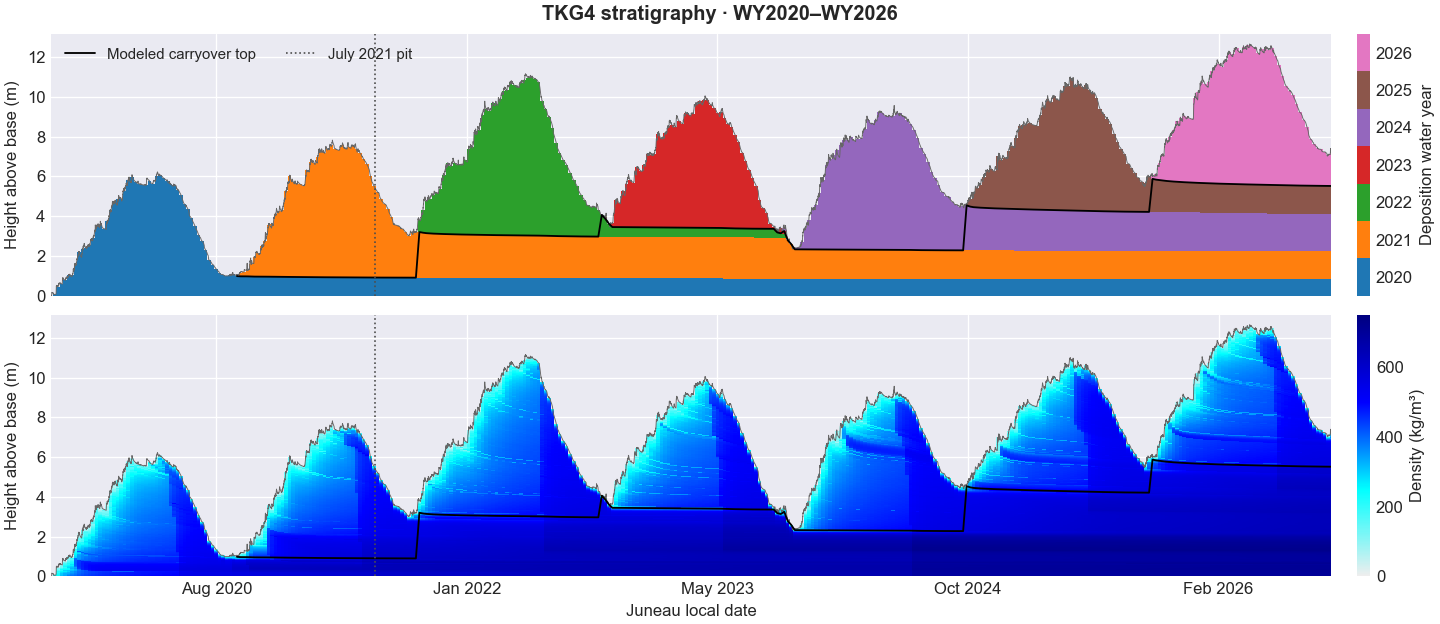

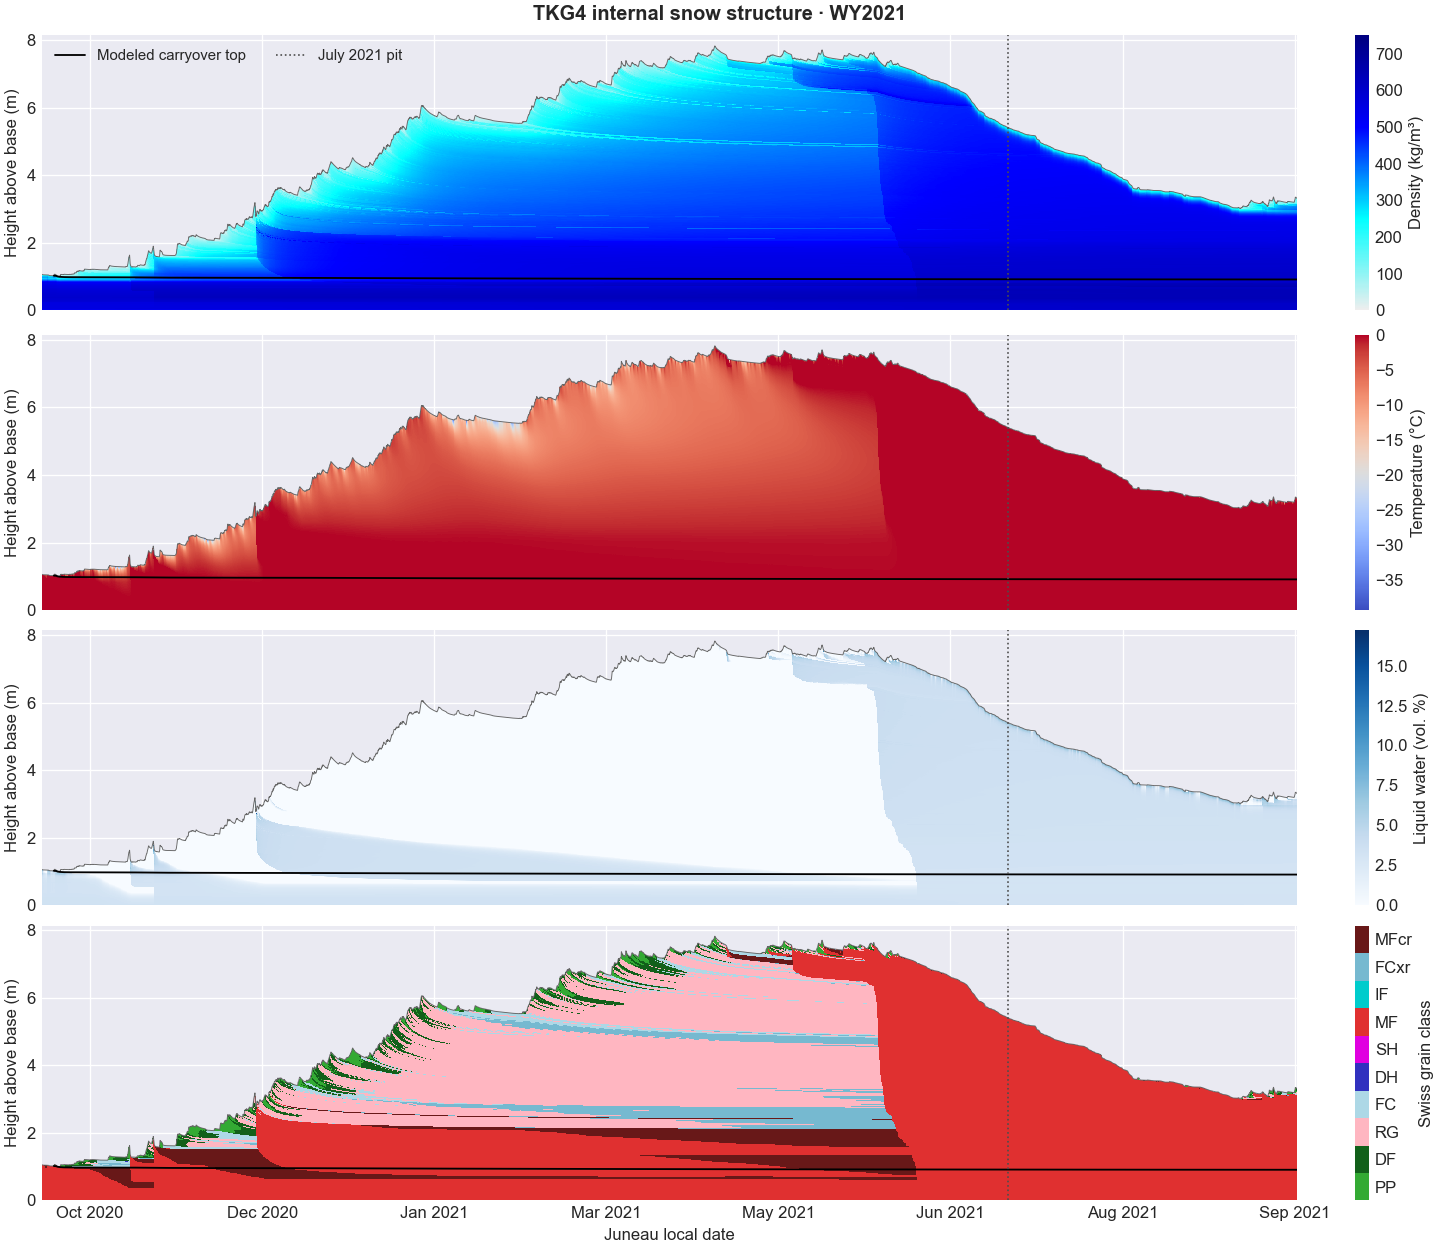

In [3]:
def dates(times):
    return mdates.date2num(times.tz_localize('UTC').tz_convert(tz))


def timeline(times, hours, title, panel_specs):
    frames = [profiles[t] for t in times]
    centers = np.repeat(dates(times), [len(frame) for frame in frames])
    layers = pd.concat(frames, ignore_index=True)
    left, right = centers - hours / 48, centers + hours / 48
    bottom, top = layers.bottom / 100, layers.top / 100
    vertices = np.stack([np.column_stack(pair) for pair in
                         [(left, bottom), (right, bottom), (right, top), (left, top)]], axis=1)
    surface = depths.loc[times[0]:times[-1]]
    boundary = np.array([basal_boundary(frame) for frame in frames]) / 100
    fig, axes = plt.subplots(len(panel_specs), 1, sharex=True, layout='constrained',
                             figsize=(12, 2.6 * len(panel_specs)))
    for ax, (field, cmap, norm, label, ticks, tick_labels) in zip(axes, panel_specs):
        values = layers[field].to_numpy()
        if field == 'grain':
            values = np.where(values == 772, 10, values.astype(int) // 100)
        bands = PolyCollection(vertices, array=values, cmap=cmap, norm=norm,
                               edgecolors='none', antialiaseds=False, rasterized=True)
        ax.add_collection(bands)
        ax.plot(dates(surface.index), surface / 100, color='.4', lw=.55)
        ax.plot(dates(times), boundary, color='black', lw=1.1, label='Modeled carryover top')
        ax.axvline(dates(pd.DatetimeIndex([pit_time]))[0], color='.3', ls=':', lw=1,
                   label='July 2021 pit')
        bar = fig.colorbar(bands, ax=ax, label=label, ticks=ticks, pad=.02)
        if tick_labels is not None:
            bar.set_ticks(ticks, labels=tick_labels)
        ax.set(ylim=(0, 1.04 * surface.max() / 100), xlim=dates(times[[0, -1]]),
               ylabel='Height above base (m)')
    axes[0].legend(loc='upper left', ncols=2, fontsize=9)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y', tz=tz))
    axes[-1].set_xlabel('Juneau local date')
    fig.suptitle(title, weight='bold')
    plt.show()


def categorical_panel(field, label, ticks, labels, colors):
    cmap = mpl.colors.ListedColormap(colors)
    norm = mpl.colors.BoundaryNorm(np.r_[ticks - .5, ticks[-1] + .5], cmap.N)
    return field, cmap, norm, label, ticks, labels


sampled = pd.concat(profiles.values(), ignore_index=True)
density_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    'density', ['#eeeeee', '#00ffff', '#0000ff', '#000080'])
density_panel = ('density', density_cmap,
                 mpl.colors.Normalize(0, np.ceil(sampled.density.max() / 50) * 50),
                 'Density (kg/m³)', None, None)
years = np.arange(2020, 2027)
timeline(weekly, 168, 'TKG4 stratigraphy · WY2020–WY2026', [
    categorical_panel('deposition_wy', 'Deposition water year', years, years,
                      plt.get_cmap('tab10').colors[:len(years)]),
    density_panel,
])
detail = pd.concat([profiles[t] for t in wy21], ignore_index=True)
timeline(wy21, 6, 'TKG4 internal snow structure · WY2021', [
    density_panel,
    ('temperature', 'coolwarm', mpl.colors.Normalize(detail.temperature.min(), 0),
     'Temperature (°C)', None, None),
    ('water', 'Blues', mpl.colors.Normalize(0, detail.water.max()),
     'Liquid water (vol. %)', None, None),
    categorical_panel('grain', 'Swiss grain class', np.arange(1, 11),
                      ['PP', 'DF', 'RG', 'FC', 'DH', 'SH', 'MF', 'IF', 'FCxr', 'MFcr'],
                      ['#33aa33', '#12601a', '#ffb6c1', '#add8e6', '#3131bf',
                       '#e000e0', '#e03030', '#00cccc', '#76b9d0', '#681818']),
])

## How the retained snow densifies

The table follows the remaining WY2020 layers at each water-year end or the last available hour. Means are thickness-weighted. Compaction, refreezing, preferential loss of layers and element merging can all affect these cohort statistics.

The archived configuration uses the default viscosity law, bucket water transport and layer combining. The initial column is empty. SNOWPACK computes bulk layer density from phase volume fractions. Settling reduces pore space and melt and refreeze change the ice and water fractions. The model's 917 kg/m³ constant is the density of pure ice. The reported maximum is from sampled profiles. Establishing limits in specific settlement and phase-change routines would require checking their source code. [Model physics](https://snowpack.slf.ch/doc-dev/html/general.html) · [Bulk density](https://snowpack.slf.ch/doc-release/html/classElementData.html) · [Phase densities](https://snowpack.slf.ch/doc-release/html/namespaceConstants.html)

In [4]:
rows = []
for stamp in annual:
    layers = profiles[stamp]
    oldest = layers.loc[layers.deposition_wy.eq(2020)]
    thickness = oldest.top - oldest.bottom
    row = {'Snapshot (UTC)': stamp, 'Column (m)': profile_depth(layers) / 100,
           'WY2020 remaining (m)': thickness.sum() / 100,
           'WY2020 max density (kg/m³)': oldest.density.max()}
    for field, label in [('density', 'density (kg/m³)'), ('temperature', 'temp. (°C)'),
                         ('water', 'water (vol. %)'), ('air', 'air (vol. %)')]:
        row[f'WY2020 mean {label}'] = (
            np.average(oldest[field], weights=thickness) if len(oldest) else np.nan
        )
    rows.append(row)
display(pd.DataFrame(rows).round(2))

old = sampled.loc[sampled.carryover]
phase_density = (917 * old.ice + 1000 * old.water + 1.1 * old.air) / 100
print(f'Largest sampled carryover layer density: {old.density.max():.1f} kg/m³')
print(f'Minimum sampled carryover air volume: {old.air.min():.1f}%')
print(f'Phase reconstruction median absolute difference: '
      f'{(old.density - phase_density).abs().median():.1f} kg/m³ '
      '(profile fractions are rounded)')

Largest sampled carryover layer density: 726.6 kg/m³
Minimum sampled carryover air volume: 21.0%
Phase reconstruction median absolute difference: 2.4 kg/m³ (profile fractions are rounded)


,Snapshot (UTC),Column (m),WY2020 remaining (m),WY2020 max density (kg/m³),WY2020 mean density (kg/m³),WY2020 mean temp. (°C),WY2020 mean water (vol. %),WY2020 mean air (vol. %)
0,2020-09-30 23:00:00,1.06,1.06,598.3,516.01,0.0,3.08,43.99
1,2021-09-30 23:00:00,3.34,0.91,651.1,626.58,0.0,3.16,31.92
2,2022-09-30 23:00:00,4.19,0.88,662.1,646.30,0.0,3.13,29.85
3,2023-09-30 23:00:00,3.29,0.86,670.3,658.53,0.0,3.10,28.52
4,2024-09-30 23:00:00,4.55,0.86,702.3,692.62,0.0,3.00,24.67
5,2025-09-30 23:00:00,5.99,0.85,706.5,697.82,0.0,3.00,24.25
6,2026-09-29 04:00:00,7.30,0.84,711.5,703.73,0.0,3.00,23.58


## July 8 pit comparison

The pit places the firn horizon at 378 cm. The density table's last interval ends at 495 cm, while the field note reports excavation to 485 cm. The plot preserves the recorded intervals and marks the reported excavation depth.

For each fully covered pit interval, the comparison averages modeled density over the same depth range, weighting the native layers by their overlap thickness. The summary also reports the percentage of matched thickness classified as modeled carryover. Profiles at the same depth can represent different deposition years.

Modeled depth 540.9 cm · Modeled carryover starts at 449.4 cm · Observed firn starts at 378 cm
Pit intervals covered: 48/48


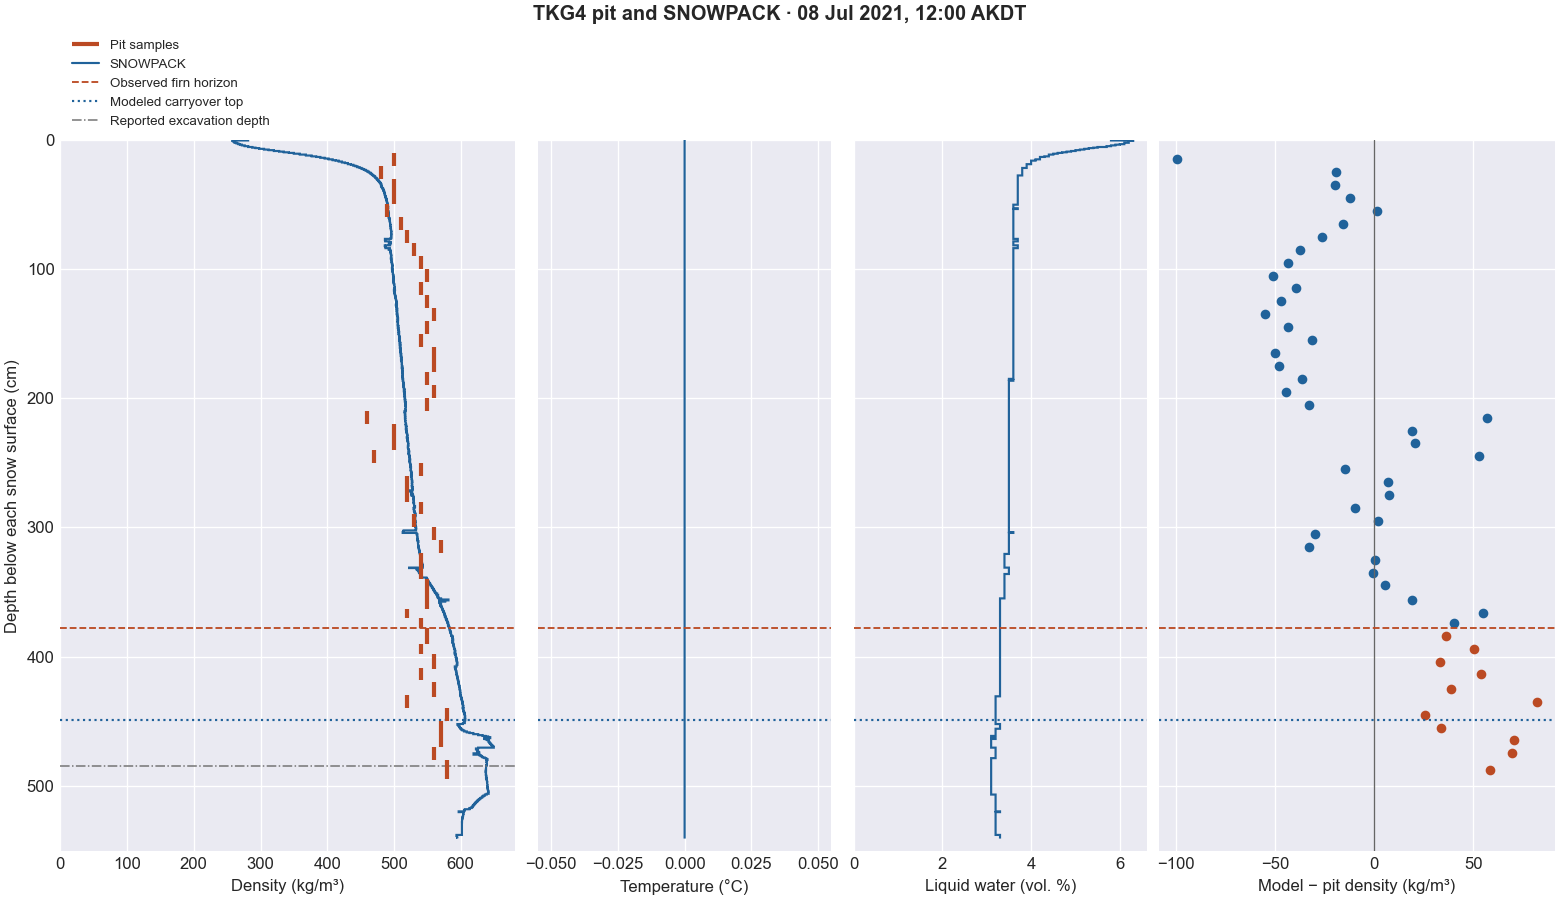

,Pit section,Matched samples,Pit mean (kg/m³),Model mean (kg/m³),Model − pit (kg/m³),Modeled carryover in matched thickness (%)
0,Seasonal snow,37,529.6,514.1,-15.5,0.0
1,Firn,11,558.6,608.5,49.9,39.0


In [5]:
with Path(pit.source).open(encoding='utf-8-sig', newline='') as stream:
    rows = iter(csv.reader(stream))
    next(row for row in rows if row[:2] == ['Depth (cm)', 'Length (cm)'])
    records = []
    for row in rows:
        if not row[0].strip():
            break
        top, thickness, _, density = map(float, row[:4])
        records.append((top, top + thickness, density * 1000))
measured = pd.DataFrame(records, columns=['top', 'bottom', 'density'])
horizon = pit.depth_cm
layers = profiles[pit_time]
depth = profile_depth(layers)
model = layers.iloc[::-1]
edges = np.r_[depth - model.top.to_numpy(), depth]
modeled_horizon = depth - basal_boundary(layers)

matched = measured.loc[measured.bottom.le(depth)].copy()
overlap = np.maximum(
    0, np.minimum(matched.bottom.to_numpy()[:, None], edges[None, 1:])
    - np.maximum(matched.top.to_numpy()[:, None], edges[None, :-1]),
)
weights = overlap.sum(axis=1)
np.testing.assert_allclose(weights, matched.bottom - matched.top)
matched['model_density'] = overlap @ model.density.to_numpy() / weights
matched['difference'] = matched.model_density - matched.density
matched['carryover_fraction'] = overlap @ model.carryover.to_numpy(dtype=float) / weights
matched['section'] = np.select(
    [matched.bottom.le(horizon), matched.top.ge(horizon)],
    ['Seasonal snow', 'Firn'], default='Across horizon',
)

fig, axes = plt.subplots(1, 4, figsize=(13, 7.5), sharey=True, layout='constrained',
                         gridspec_kw={'width_ratios': [1.55, 1, 1, 1.35]})
profile_ax, temp_ax, water_ax, difference_ax = axes
model_color, pit_color = '#20629a', '#bb4a23'
profile_ax.vlines(measured.density, measured.top, measured.bottom,
                  color=pit_color, lw=2.5, label='Pit samples', zorder=4)
for ax, field, label in zip(axes, ('density', 'temperature', 'water'),
                            ('Density (kg/m³)', 'Temperature (°C)', 'Liquid water (vol. %)')):
    ax.stairs(model[field], edges, orientation='horizontal', baseline=None,
              color=model_color, linewidth=1.3, label='SNOWPACK')
    ax.set_xlabel(label)

difference_ax.axvline(0, color='.4', lw=.8)
summary = []
for section, group in matched.groupby('section', sort=False):
    difference_ax.scatter(group.difference, (group.top + group.bottom) / 2, s=23,
                          color=pit_color if section == 'Firn' else model_color)
    lengths = group.bottom - group.top
    summary.append({
        'Pit section': section, 'Matched samples': len(group),
        'Pit mean (kg/m³)': np.average(group.density, weights=lengths),
        'Model mean (kg/m³)': np.average(group.model_density, weights=lengths),
        'Model − pit (kg/m³)': np.average(group.difference, weights=lengths),
        'Modeled carryover in matched thickness (%)':
            100 * np.average(group.carryover_fraction, weights=lengths),
    })
difference_ax.set_xlabel('Model − pit density (kg/m³)')
for ax in axes:
    ax.axhline(horizon, color=pit_color, ls='--', lw=1.1, label='Observed firn horizon')
    if np.isfinite(modeled_horizon):
        ax.axhline(modeled_horizon, color=model_color, ls=':', lw=1.3,
                   label='Modeled carryover top')
profile_ax.axhline(485, color='.45', ls='-.', lw=.9, label='Reported excavation depth')
profile_ax.set(ylabel='Depth below each snow surface (cm)',
               ylim=(max(depth, measured.bottom.max()) + 10, 0))
profile_ax.legend(loc='lower left', bbox_to_anchor=(0, 1), frameon=False, fontsize=8)
fig.suptitle(f'TKG4 pit and SNOWPACK · {snapshot:%d %b %Y, %H:%M %Z}', weight='bold')
plt.show()

print(f'Modeled depth {depth:.1f} cm · Modeled carryover starts at {modeled_horizon:.1f} cm '
      f'· Observed firn starts at {horizon:g} cm')
print(f'Pit intervals covered: {len(matched)}/{len(measured)}')
display(pd.DataFrame(summary).round(1))

## Interpretation

- About **0.84 m of WY2020 snow remained** at the end of the run. Its thickness-weighted density rose from **516 to 704 kg/m³** between the late-September 2020 and 2026 snapshots, while its mean air fraction fell from **44% to 24%**. The highest sampled carryover layer density was **727 kg/m³**. The declining air fraction and rising density show that the retained material continued to densify over the analysis period.
- The simulated column was **5.41 m deep** and at **0 °C** throughout the July 8 snapshot. The modeled carryover starts at **4.49 m** below the surface, about **71 cm deeper** than the observed firn horizon.
- All **48** density intervals are covered by the model. In the 11 intervals below the observed horizon, modeled density averaged **609 kg/m³** versus **559 kg/m³** in the pit. Only **39%** of that matched thickness is age-classified as carryover in the model, so the **+50 kg/m³** difference combines a horizon-depth offset with differences in the simulated density profile.

## Density columns at the July 8 pit

Each band spans one measured density interval or one native model layer. Both columns use the same density scale and start at zero depth below their own snow surfaces. Blank areas in the pit column indicate unsampled depths. Eleven measured intervals begin at or below the observed firn horizon at 378 cm. The model's age-based carryover begins at 449 cm. Both lines extend across the two columns to show the offset.

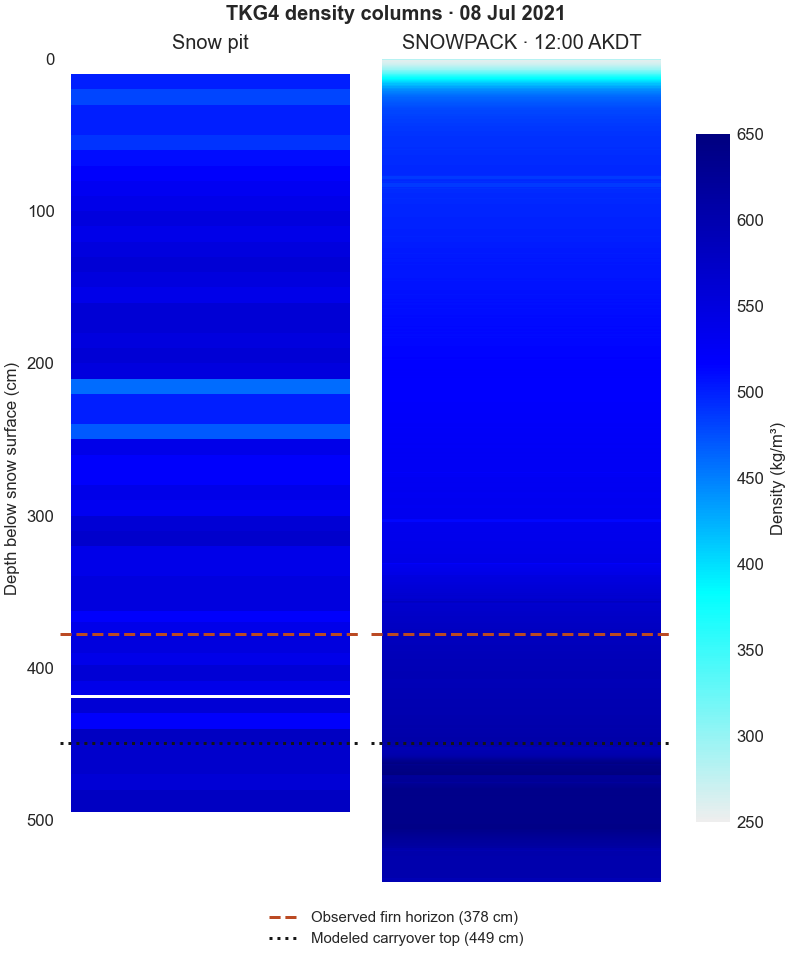

In [6]:
modeled = pd.DataFrame({
    'top': edges[:-1], 'bottom': edges[1:], 'density': model.density.to_numpy(),
})
min_density = min(measured.density.min(), modeled.density.min())
max_density = max(measured.density.max(), modeled.density.max())
column_norm = mpl.colors.Normalize(
    50 * np.floor(min_density / 50), 50 * np.ceil(max_density / 50),
)
fig, axes = plt.subplots(1, 2, figsize=(6.6, 8), sharey=True, layout='constrained')
fig.suptitle(f'TKG4 density columns · {snapshot:%d %b %Y}', weight='bold')
max_depth = max(measured.bottom.max(), modeled.bottom.max())

for ax, (label, column) in zip(
    axes, [('Snow pit', measured), (f'SNOWPACK · {snapshot:%H:%M %Z}', modeled)],
):
    vertices = [[(0, top), (1, top), (1, bottom), (0, bottom)]
                for top, bottom in zip(column.top, column.bottom)]
    bands = PolyCollection(vertices, array=column.density.to_numpy(), cmap=density_cmap,
                           norm=column_norm, edgecolors='none')
    ax.set_facecolor('white')
    ax.grid(False)
    ax.add_collection(bands)
    ax.axhline(horizon, color=pit_color, ls='--', lw=1.8)
    ax.axhline(modeled_horizon, color='#161616', ls=':', lw=1.8)
    ax.set(title=label, xlim=(-.04, 1.04), ylim=(max_depth + 10, 0), xticks=[])
    ax.spines[['left', 'right', 'top', 'bottom']].set_color('.75')

axes[0].set_ylabel('Depth below snow surface (cm)')
handles = [
    mpl.lines.Line2D([], [], color=pit_color, ls='--', lw=1.8,
                     label=f'Observed firn horizon ({horizon:g} cm)'),
    mpl.lines.Line2D([], [], color='#161616', ls=':', lw=1.8,
                     label=f'Modeled carryover top ({modeled_horizon:.0f} cm)'),
]
fig.legend(handles=handles, loc='outside lower center', frameon=False, fontsize=9)
fig.colorbar(bands, ax=axes, label='Density (kg/m³)', shrink=.82, pad=.04)
plt.show()